# 06 — Transformer experiments

**Objective.** Test whether a multilingual transformer beats TF-IDF on the same splits. Training is run by `python -m ml.training.train_transformer` (CPU, ~10 minutes); this notebook reads its saved metrics instead of retraining.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4)
from ml.config import PROCESSED_DATASET, ARTIFACTS_DIR, METADATA_DIR, RAW_DIR
df = pd.read_csv(PROCESSED_DATASET)
print(f'{len(df):,} processed fact-checks')

4,137 processed fact-checks


In [2]:
p = ARTIFACTS_DIR / 'transformer' / 'transformer_metrics.json'
tm = json.loads(p.read_text()) if p.exists() else None
print('metrics found' if tm else 'run python -m ml.training.train_transformer first')

metrics found


In [3]:
if tm:
    rows = {'classical LR (deployed)': tm.get('classical_reference', {})}
    if 'frozen_embeddings_lr' in tm: rows['MiniLM frozen + LR'] = {'validation_macro_f1': tm['frozen_embeddings_lr']['validation']['f1_macro'], 'test_macro_f1': tm['frozen_embeddings_lr']['test']['f1_macro']}
    if 'finetune' in tm: rows['MiniLM fine-tuned'] = {'validation_macro_f1': tm['finetune']['validation']['f1_macro'], 'test_macro_f1': tm['finetune']['test']['f1_macro']}
    display(pd.DataFrame(rows).T)

,model,validation_macro_f1,test_macro_f1
classical LR (deployed),logistic_regression,0.5841,0.527
MiniLM frozen + LR,NaN,0.5136,0.5092
MiniLM fine-tuned,NaN,0.5898,0.56


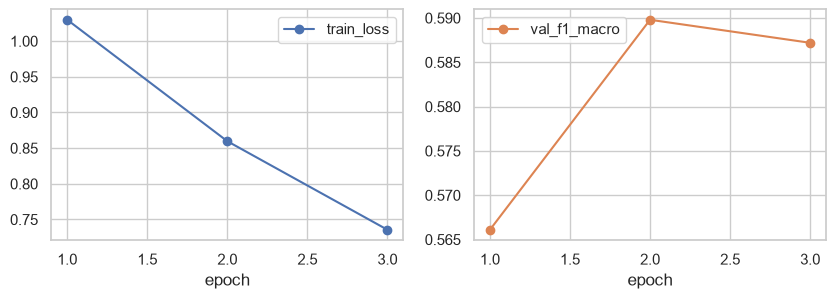

,train_loss,val_f1_macro,val_accuracy
epoch,,,
1,1.0299,0.5661,0.5934
2,0.8597,0.5898,0.6069
3,0.7356,0.5872,0.6050


In [4]:
if tm and 'finetune' in tm:
    h = pd.DataFrame(tm['finetune']['history']).set_index('epoch')
    h[['train_loss','val_f1_macro']].plot(marker='o', subplots=True, layout=(1,2), figsize=(10,3)); plt.show(); display(h)

## Observations
* Frozen sentence embeddings + LR are *worse* than TF-IDF: the paraphrase model encodes topic, not verdict type.
* Full fine-tuning ties LR on validation (0.590 vs 0.584) and beats it on test (0.560 vs 0.527) with far better calibration, at ~3 minutes of CPU per epoch.
* LR stays deployed for now (validation tie, exact SHAP, lower RAM); the transformer is the first candidate to deploy once it has an explainer and repeated-seed evaluation.

**Conclusion.** Frozen embeddings lose to TF-IDF; fine-tuning wins modestly. Transformers are not automatically better on ~2.6k short, noisy claims. Bigger Indic models (IndicBERT v2, MuRIL) on a GPU are the next experiment.